In [3]:
import matplotlib.pyplot as plt

In [4]:
#Gradient decent intuition

# y = 2x

theta = [-2,-1, 2, 3, 4, 5]
x = [0,1,2,3,4,5]
y_act = [2*i for i in x]
err = []

for t in theta:
    y_pred = [t*i for i in x]
    err.append(1/2*len(y_act)*sum([(y_act[i]-y_pred[i])**2 for i in range(len(y_act))]))


In [2]:
err

[2640.0, 1485.0, 0.0, 165.0, 660.0, 1485.0]

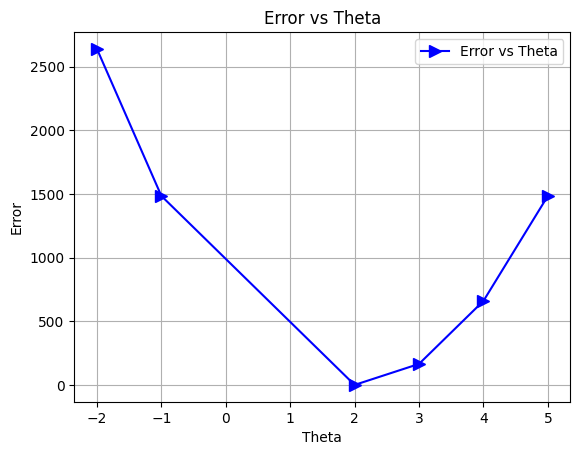

In [19]:
plt.plot(theta, err, color='blue', label='Error vs Theta', marker='>', markersize=8)
plt.xlabel('Theta')
plt.ylabel('Error')
plt.title('Error vs Theta')
plt.legend()
plt.grid()

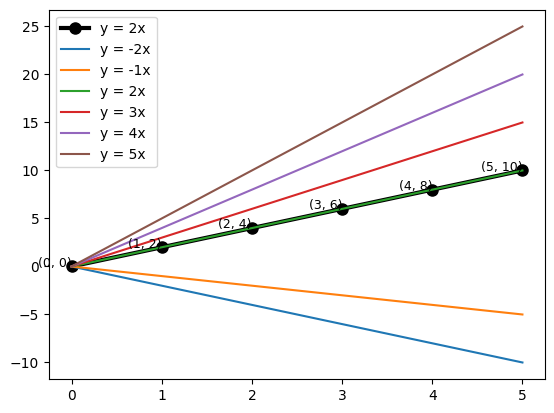

In [20]:
plt.plot(x, y_act, color='black', label='y = 2x', linewidth=3, marker='o', markersize=8)

for i in theta:
    plt.plot(x, [i*j for j in x], label=f'y = {i}x')

plt.legend()    
for i in range(len(x)):
    plt.text(x[i], y_act[i], f'({x[i]}, {y_act[i]})', fontsize=9, ha='right')

plt.show()

In [68]:
import pandas as pd
df = pd.read_csv('../data/insurance.csv')

In [71]:
df.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


In [70]:
df = pd.get_dummies(columns=['sex', 'smoker', 'region'], data=df, drop_first=True, dtype=int)

In [72]:
df['smoker_charges'] = df['smoker_yes'] * df['charges']
df['bmi_charges'] = df['bmi'] * df['charges']

In [73]:
X = df.drop(columns=['charges'])
y = df['charges']


In [74]:
X.dtypes

age                   int64
bmi                 float64
children              int64
sex_male              int64
smoker_yes            int64
region_northwest      int64
region_southeast      int64
region_southwest      int64
smoker_charges      float64
bmi_charges         float64
dtype: object

In [75]:
X.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,smoker_charges,bmi_charges
0,19,27.900,0,0,1,0,0,1,16884.924,471089.379600
1,18,33.770,1,1,0,0,1,0,0.000,58271.901171
2,28,33.000,3,1,0,0,1,0,0.000,146832.246000
3,33,22.705,0,1,0,1,0,0,0.000,499157.405200
4,32,28.880,0,1,0,1,0,0,0.000,111674.778176


In [76]:
X.dtypes

age                   int64
bmi                 float64
children              int64
sex_male              int64
smoker_yes            int64
region_northwest      int64
region_southeast      int64
region_southwest      int64
smoker_charges      float64
bmi_charges         float64
dtype: object

In [77]:
# need to convert to non-null values for each column, and check the data types of each column to ensure they are suitable for modeling.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1338 non-null   int64  
 1   bmi               1338 non-null   float64
 2   children          1338 non-null   int64  
 3   charges           1338 non-null   float64
 4   sex_male          1338 non-null   int64  
 5   smoker_yes        1338 non-null   int64  
 6   region_northwest  1338 non-null   int64  
 7   region_southeast  1338 non-null   int64  
 8   region_southwest  1338 non-null   int64  
 9   smoker_charges    1338 non-null   float64
 10  bmi_charges       1338 non-null   float64
dtypes: float64(4), int64(7)
memory usage: 115.1 KB


In [78]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [79]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [80]:
model.coef_, model.intercept_

(array([ 4.96983332e+01, -2.65668511e+02,  7.25940248e+01, -1.74552927e+02,
         5.68901149e+03,  9.29234973e+01, -6.27841192e+01, -1.39921339e+02,
        -9.43839201e-02,  2.70707016e-02]),
 np.float64(7563.934387734499))

In [81]:
print("Interscept:", model.intercept_)

for coef, col in zip(model.coef_, X.columns):
    print(f"{col}: {coef}")

Interscept: 7563.934387734499
age: 49.69833324929859
bmi: -265.6685108378026
children: 72.59402482287584
sex_male: -174.55292734854234
smoker_yes: 5689.011491253432
region_northwest: 92.92349733293106
region_southeast: -62.78411923319841
region_southwest: -139.92133944305732
smoker_charges: -0.09438392007799734
bmi_charges: 0.027070701578509215


In [82]:
y_pred = model.predict(X_test)

In [83]:
X_test.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,smoker_charges,bmi_charges
764,45,25.175,2,0,0,0,0,0,0.00000,2.289683e+05
887,36,30.020,0,0,0,1,0,0,0.00000,1.582707e+05
890,64,26.885,0,0,1,1,0,0,29330.98315,7.885635e+05
1293,46,25.745,3,1,0,1,0,0,0.00000,2.394772e+05
259,19,31.920,0,1,1,1,0,0,33750.29180,1.077309e+06


In [84]:
X_test['actual_charges'] = y_test
X_test['predicted_charges'] = y_pred
X_test['manual_calculated_charges'] = X_test['age']*model.coef_[0] + X_test['bmi']*model.coef_[1] + X_test['children']*model.coef_[2] + X_test['sex_male']*model.coef_[3] + X_test['smoker_yes']*model.coef_[4] + X_test['region_northwest']*model.coef_[5] + X_test['region_southeast']*model.coef_[6] + X_test['region_southwest']*model.coef_[7] + model.intercept_   

In [85]:
X_test.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,smoker_charges,bmi_charges,actual_charges,predicted_charges,manual_calculated_charges
764,45,25.175,2,0,0,0,0,0,0.00000,2.289683e+05,9095.06825,9455.676363,3257.342673
887,36,30.020,0,0,0,1,0,0,0.00000,1.582707e+05,5272.17580,5755.128549,1470.629187
890,64,26.885,0,0,1,1,0,0,29330.98315,7.885635e+05,29330.98315,27962.658318,9384.064790
1293,46,25.745,3,1,0,1,0,0,0.00000,2.394772e+05,9301.89355,9629.391705,3146.574550
259,19,31.920,0,1,1,1,0,0,33750.29180,1.077309e+06,33750.29180,31613.480025,5635.445915


In [89]:


#R2, adjusted R2

from sklearn.metrics import r2_score, mean_squared_error

r2 = r2_score(y_test, y_pred)
r2

0.9749223001145891

In [93]:
ms = mean_squared_error(y_test, y_pred)

import numpy as np
rms = np.sqrt(ms)

In [94]:
ms

3784002.7168786745

In [95]:
rms

np.float64(1945.2513248623363)

In [87]:
y_pred_train = model.predict(X_train)

r2_train = r2_score(y_train, y_pred_train)

adj_r2 = 1 - (1-r2_train)*(len(y_train)-1)/(len(y_train)-X_train.shape[1]-1)
adj_r2

0.9815581167090038

In [ ]:
#0.7672642952734356 - r2
#0.7429028610548283 - adjusted r2
